<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/particle_physics/particle_ch03to05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Particle Physics* — `particle_ch03to05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Particle Physics Ch 3–5 Figures — Colab Notebook
**Particle Physics · Chapters 3–5 (Strong Force, Weak Force, BSM)**

| Figure | Chapter | Section | Content |
|--------|---------|---------|--------|
| ch03/fig01 | Ch 3 | §3.2 | $\alpha_s(\mu)$ running + $R$-ratio |
| ch03/fig02 | Ch 3 | §3.2 | Quark-antiquark potential $V(r)$ & string breaking |
| ch03/fig03 | Ch 3 | §3.4 | Hadron multiplets: meson octet & baryon decuplet |
| ch04/fig01 | Ch 4 | §4.2 | Parity violation: Wu experiment schematic |
| ch04/fig02 | Ch 4 | §4.3 | Higgs potential & SSB |
| ch04/fig03 | Ch 4 | §4.5 | Neutrino oscillation probability vs $L/E$ |
| ch05/fig01 | Ch 5 | §5.1 | Hierarchy problem: scale of corrections |
| ch05/fig02 | Ch 5 | §5.2–3 | Galaxy rotation curve + CMB spectrum + Universe budget |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, Circle, Wedge, FancyArrowPatch
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
TEAL='#2ec4b6'; BLUE='#7ec8e3'; YELL='#f9c74f'
GREEN='#90ee90'; RED='#e07070'; PURP='#c792ea'; ORAN='#ffa657'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':TEAL,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})

for ch in ['ch03','ch04','ch05']:
    os.makedirs(f'figures/{ch}', exist_ok=True)

def save(path, fig=None):
    f = fig or plt.gcf()
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')

Setup complete.


---
## Ch3/fig01 · Running $\alpha_s$ and $R$-ratio (§3.2)

  saved -> figures/ch03/fig01_alphas_R.png


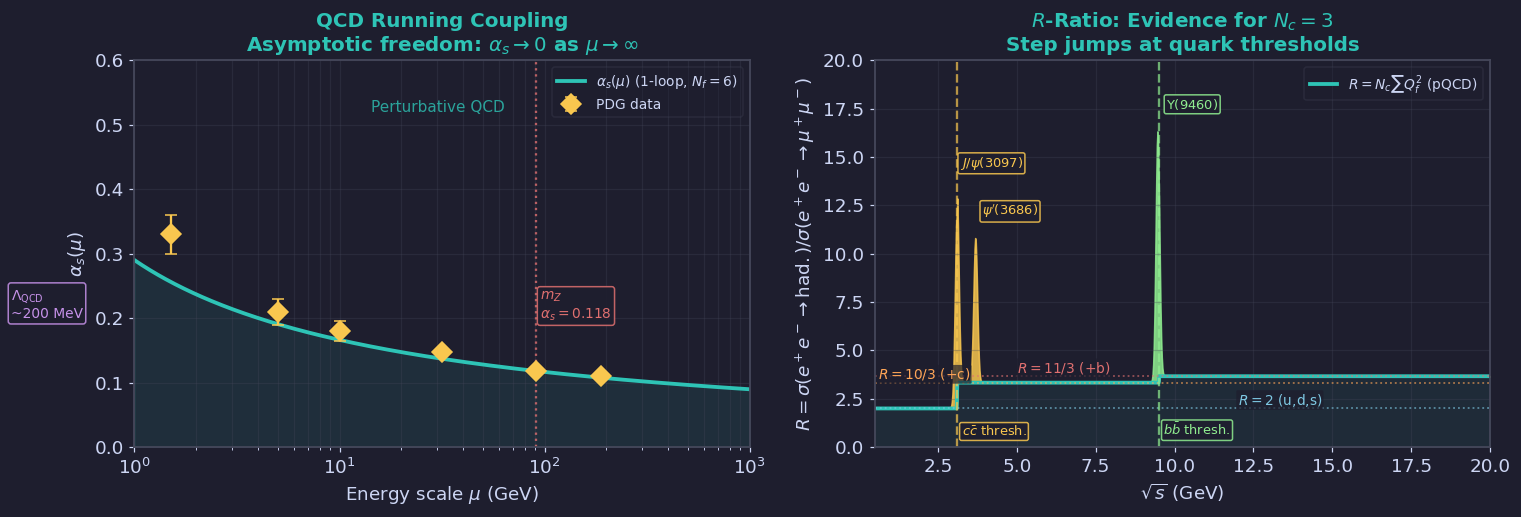

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# ── Left: alpha_s running (correct 1-loop formula) ────────────────────────
ax = axes[0]; ax.set_facecolor(BG)

mZ = 91.2; as_mZ = 0.118; b0 = 7.0   # b0 = 11 - 2*Nf/3, Nf=6
mu_arr = np.logspace(np.log10(1.0), np.log10(1000), 400)
# 1-loop: alpha_s(mu) = alpha_s(m_Z) / (1 + alpha_s(m_Z)*b0/(2pi)*ln(mu/m_Z))
alpha_s = as_mZ / (1 + as_mZ*b0/(2*np.pi)*np.log(mu_arr/mZ))
alpha_s = np.clip(alpha_s, 0.04, 0.99)

ax.semilogx(mu_arr, alpha_s, color=TEAL, lw=2.5, label=r'$\alpha_s(\mu)$ (1-loop, $N_f=6$)')
ax.fill_between(mu_arr, 0, alpha_s, color=TEAL, alpha=0.10)

data_mu  = [1.5, 5.0, 10.0, 31.6, 91.2, 189.0]
data_as  = [0.33, 0.21, 0.18, 0.147, 0.118, 0.110]
data_err = [0.03, 0.02, 0.015, 0.005, 0.002, 0.005]
ax.errorbar(data_mu, data_as, yerr=data_err, fmt='D', color=YELL,
            ms=9, capsize=4, elinewidth=1.5, label='PDG data', zorder=5)

ax.axvline(91.2, color=RED, lw=1.5, ls=':', alpha=0.8)
ax.text(95, 0.2, r'$m_Z$'+'\n'+r'$\alpha_s=0.118$', fontsize=9, color=RED,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=RED, alpha=0.85))
ax.axvline(0.21, color=PURP, lw=1.5, ls=':', alpha=0.7)
ax.text(0.25, 0.20, r'$\Lambda_{\rm QCD}$'+'\n~200 MeV', fontsize=9, color=PURP,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=PURP, alpha=0.85))
ax.text(30, 0.52, 'Perturbative QCD', ha='center', fontsize=10, color=TEAL, alpha=0.8)

ax.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax.set_ylabel(r'$\alpha_s(\mu)$')
ax.set_title('QCD Running Coupling\n'+r'Asymptotic freedom: $\alpha_s\to 0$ as $\mu\to\infty$')
ax.legend(fontsize=9, labelcolor=FG)
ax.set_xlim(1, 1000); ax.set_ylim(0, 0.60)
ax.grid(True, which='both', alpha=0.3)

# ── Right: R-ratio (resonances as Gaussian spikes, labels clear) ──────────
ax2 = axes[1]; ax2.set_facecolor(BG)
sqrt_s = np.linspace(0.5, 20, 1000)
Nc = 3
R_uds   = Nc*(4/9 + 1/9 + 1/9)          # = 2.0
R_udsc  = Nc*(4/9 + 1/9 + 1/9 + 4/9)    # = 10/3
R_udscb = Nc*(4/9 + 1/9 + 1/9 + 4/9 + 1/9)  # = 11/3

R_theory = np.where(sqrt_s < 3.1, R_uds,
           np.where(sqrt_s < 9.5, R_udsc, R_udscb))
ax2.plot(sqrt_s, R_theory, color=TEAL, lw=2.5,
         label=r'$R = N_c\sum Q_f^2$ (pQCD)')
ax2.fill_between(sqrt_s, 0, R_theory, color=TEAL, alpha=0.08)

# Resonance peaks as narrow Gaussian spikes
for E_res, R_peak, lbl, col in [
    (3.097, 10.0, r'$J/\psi$(3097)', YELL),
    (3.686,  7.5, r"$\psi'$(3686)",  YELL),
    (9.460, 13.0, r'$\Upsilon$(9460)', GREEN),
]:
    spike = R_peak * np.exp(-0.5*((sqrt_s-E_res)/0.06)**2)
    ax2.fill_between(sqrt_s, R_theory, R_theory+spike, color=col, alpha=0.85)
    ax2.text(E_res+1.1, R_peak+4.5, lbl, ha='center', fontsize=8.5, color=col,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.85))

# R-level labels
for R_val, lbl, col, x_ in [(R_uds, r'$R=2$ (u,d,s)', BLUE, 12.0),
                         (R_udsc, r'$R=10/3$ (+c)', ORAN, 0.6),
                         (R_udscb, r'$R=11/3$ (+b)', RED, 5.0)]:
    ax2.axhline(R_val, color=col, lw=1.2, ls=':', alpha=0.6)
    ax2.text(x_, R_val+0.20, lbl, fontsize=9, color=col,
             bbox=dict(boxstyle='round,pad=0.1', fc=BG, ec='none', alpha=0.7))

# Threshold markers above data
for E_th, lbl, col in [(3.1, r'$c\bar c$ thresh.', YELL),
                        (9.5, r'$b\bar b$ thresh.', GREEN)]:
    ax2.axvline(E_th, color=col, lw=1.5, ls='--', alpha=0.7)
    ax2.text(E_th+0.15, 0.6, lbl, fontsize=8.5, color=col,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.85))

ax2.set_xlabel(r'$\sqrt{s}$ (GeV)')
ax2.set_ylabel(r'$R = \sigma(e^+e^-\to{\rm had.})/\sigma(e^+e^-\to\mu^+\mu^-)$')
ax2.set_title(r'$R$-Ratio: Evidence for $N_c=3$'+'\nStep jumps at quark thresholds')
ax2.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax2.set_xlim(0.5, 20); ax2.set_ylim(0, 20)
ax2.grid(True, alpha=0.3)

plt.tight_layout(pad=1.5)
save('figures/ch03/fig01_alphas_R.png', fig)


---
## Ch3/fig02 · QCD Potential & String Breaking (§3.2)

  saved -> figures/ch03/fig02_potential.png


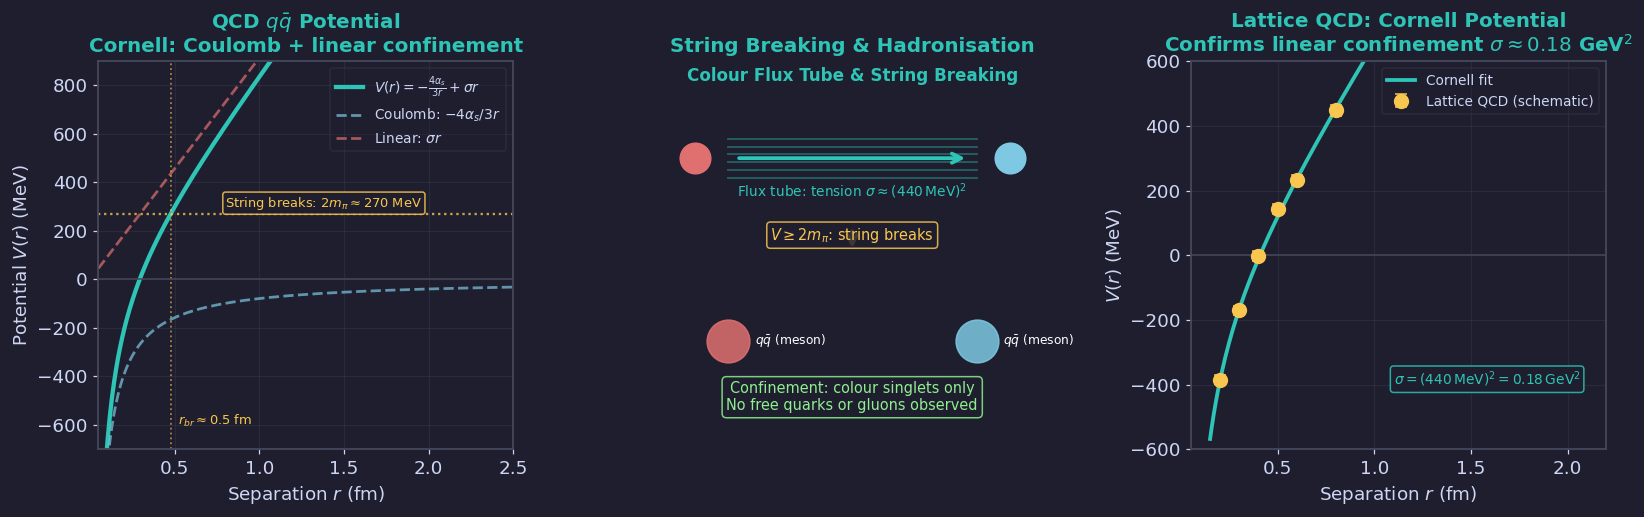

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)
hbarc = 0.197   # GeV·fm

# ── Left: Cornell potential (FIX r_break, correct unit conversion) ────────
ax = axes[0]; ax.set_facecolor(BG)
r = np.linspace(0.05, 2.5, 400)   # fm
alpha_s_val = 0.3; sigma_val = 0.18  # GeV²
r_gev = r / hbarc   # fm → GeV^{-1}

V_GeV = -4*alpha_s_val/(3*r_gev) + sigma_val*r_gev
V_MeV = V_GeV * 1000
V_c_MeV = -4*alpha_s_val/(3*r_gev) * 1000
V_l_MeV =  sigma_val * r_gev * 1000

ax.plot(r, V_MeV, color=TEAL, lw=2.8, label=r'$V(r)=-\frac{4\alpha_s}{3r}+\sigma r$')
ax.plot(r, V_c_MeV, color=BLUE, lw=1.8, ls='--', alpha=0.7, label=r'Coulomb: $-4\alpha_s/3r$')
ax.plot(r, V_l_MeV, color=RED,  lw=1.8, ls='--', alpha=0.7, label=r'Linear: $\sigma r$')

V_break = 270.0
if np.any(V_MeV >= V_break):
    r_break = r[np.argmax(V_MeV >= V_break)]
    ax.axhline(V_break, color=YELL, lw=1.5, ls=':', alpha=0.8)
    ax.axvline(r_break, color=YELL, lw=1.2, ls=':', alpha=0.6)
    ax.text(0.8, V_break+30, r'String breaks: $2m_\pi\approx 270$ MeV',
            fontsize=8.5, color=YELL,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=YELL, alpha=0.85))
    ax.text(r_break+0.04, -600, fr'$r_{{br}}\approx${r_break:.1f} fm', fontsize=8.5, color=YELL)

ax.axhline(0, color=EDGE, lw=1)
ax.set_xlabel(r'Separation $r$ (fm)')
ax.set_ylabel(r'Potential $V(r)$ (MeV)')
ax.set_title(r'QCD $q\bar q$ Potential'+'\nCornell: Coulomb + linear confinement')
ax.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax.set_xlim(0.05, 2.5); ax.set_ylim(-700, 900)
ax.grid(True, alpha=0.3)

# ── Middle: Flux tube & string breaking ───────────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_xlim(0,1); ax2.set_ylim(0,1)
ax2.text(0.5,0.95,'Colour Flux Tube & String Breaking',ha='center',
         fontsize=11,color=TEAL,fontweight='bold')
ax2.plot(0.12,0.75,'o',color=RED,ms=20,zorder=5)
ax2.text(0.12,0.75,'q',ha='center',va='center',fontsize=13,color='white',fontweight='bold')
ax2.plot(0.88,0.75,'o',color=BLUE,ms=20,zorder=5)
ax2.text(0.88,0.75,r'$\bar q$',ha='center',va='center',fontsize=13,color='white',fontweight='bold')
for y_f in np.linspace(0.70,0.80,6):
    ax2.plot([0.20,0.80],[y_f,y_f],color=TEAL,lw=1.2,alpha=0.4)
ax2.annotate('',xy=(0.78,0.75),xytext=(0.22,0.75),
             arrowprops=dict(arrowstyle='->',color=TEAL,lw=2.5,mutation_scale=15))
ax2.text(0.5,0.65,r'Flux tube: tension $\sigma\approx(440\,\rm MeV)^2$',
         ha='center',fontsize=9,color=TEAL)
ax2.annotate('',xy=(0.5,0.51),xytext=(0.5,0.57),
             arrowprops=dict(arrowstyle='->',color=YELL,lw=2.5,mutation_scale=15))
ax2.text(0.5,0.54,r'$V\geq 2m_\pi$: string breaks',ha='center',fontsize=9.5,color=YELL,
         bbox=dict(boxstyle='round,pad=0.25',fc=BG,ec=YELL,alpha=0.85))
for xc,lbl,col in [(0.20,r'$q\bar q$ (meson)',RED),(0.80,r'$q\bar q$ (meson)',BLUE)]:
    ax2.plot(xc,0.28,'o',color=col,ms=28,zorder=5,alpha=0.85)
    ax2.text(xc+0.15,0.28,lbl,ha='center',va='center',fontsize=8,color='white')
ax2.text(0.5,0.10,
         r'Confinement: colour singlets only'+'\n'+r'No free quarks or gluons observed',
         ha='center',fontsize=9.5,color=GREEN,
         bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=GREEN,alpha=0.85))
ax2.set_title('String Breaking & Hadronisation',color=TEAL)

# ── Right: Lattice QCD schematic data ────────────────────────────────────
ax3 = axes[2]; ax3.set_facecolor(BG)
r_lat = np.array([0.2,0.3,0.4,0.5,0.6,0.8,1.0,1.2,1.5,2.0])
np.random.seed(42)
V_lat_gev = -4*0.3/(3*r_lat/hbarc) + 0.18*r_lat/hbarc - 0.18
V_lat_err = 0.012 + 0.006*r_lat
V_lat_data = V_lat_gev + np.random.normal(0, V_lat_err)
ax3.errorbar(r_lat, V_lat_data*1000, yerr=V_lat_err*1000, fmt='o',
             color=YELL, ms=9, capsize=4, elinewidth=1.5,
             label='Lattice QCD (schematic)', zorder=5)
r_fit = np.linspace(0.15, 2.1, 200)
V_fit = (-4*0.3/(3*r_fit/hbarc) + 0.18*r_fit/hbarc - 0.18)*1000
ax3.plot(r_fit, V_fit, color=TEAL, lw=2.5, label='Cornell fit')
ax3.axhline(0, color=EDGE, lw=1)
ax3.text(1.1, -400, r'$\sigma=(440\,{\rm MeV})^2=0.18\,{\rm GeV}^2$',
         fontsize=9, color=TEAL,
         bbox=dict(boxstyle='round,pad=0.25',fc=BG,ec=TEAL,alpha=0.85))
ax3.set_xlabel('Separation $r$ (fm)')
ax3.set_ylabel('$V(r)$ (MeV)')
ax3.set_title('Lattice QCD: Cornell Potential\n'+
              r'Confirms linear confinement $\sigma\approx 0.18$ GeV$^2$')
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_ylim(-600, 600)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.5)
save('figures/ch03/fig02_potential.png', fig)


---
## Ch04/fig02 · Higgs Potential & SSB (§4.3)

  saved -> figures/ch04/fig02_higgs.png


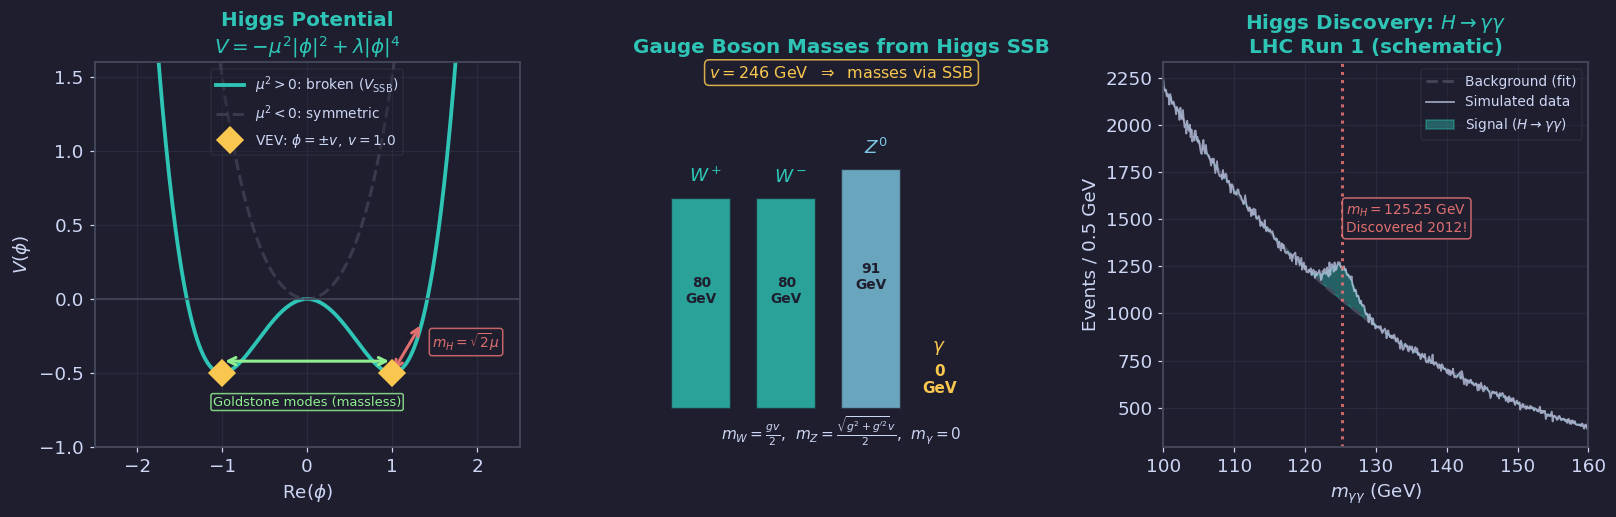

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Higgs potential (correct VEV: phi=±v where v=sqrt(mu^2/2lam)) ──
ax = axes[0]; ax.set_facecolor(BG)
phi = np.linspace(-2.5, 2.5, 400)
mu2 = 1.0; lam = 0.5
v = np.sqrt(mu2/(2*lam))   # VEV = sqrt(mu^2/2lambda)
V_ssb  = -mu2*phi**2 + lam*phi**4
V_symm = +mu2*phi**2 + lam*phi**4
V_min  = -mu2*v**2 + lam*v**4

ax.plot(phi, V_ssb,  color=TEAL, lw=2.5, label=r'$\mu^2>0$: broken ($V_{\rm SSB}$)')
ax.plot(phi, V_symm, color=EDGE, lw=2.0, ls='--', alpha=0.7, label=r'$\mu^2<0$: symmetric')
ax.plot([-v, v], [V_min, V_min], 'D', color=YELL, ms=12, zorder=5,
        label=fr'VEV: $\phi=\pm v,\;v={v:.1f}$')

x_h = v + 0.35; V_h = -mu2*x_h**2 + lam*x_h**4
ax.annotate('', xy=(x_h, V_h), xytext=(v, V_min),
            arrowprops=dict(arrowstyle='<->', color=RED, lw=2))
ax.text(x_h+0.12, (V_min+V_h)/2, r'$m_H=\sqrt{2}\mu$', fontsize=9, color=RED,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=RED, alpha=0.85))
ax.annotate('', xy=(-v, V_min+0.08), xytext=(v, V_min+0.08),
            arrowprops=dict(arrowstyle='<->', color=GREEN, lw=2))
ax.text(0, V_min-0.22, r'Goldstone modes (massless)', ha='center', fontsize=8.5, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=GREEN, alpha=0.85))

ax.axhline(0, color=EDGE, lw=1)
ax.set_xlabel(r'$\mathrm{Re}(\phi)$'); ax.set_ylabel(r'$V(\phi)$')
ax.set_title('Higgs Potential\n'+r'$V=-\mu^2|\phi|^2+\lambda|\phi|^4$')
ax.legend(fontsize=9, labelcolor=FG, loc='upper center')
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.0, 1.6)
ax.grid(True, alpha=0.3)

# ── Middle: W/Z mass bar chart (text colour readable on coloured bars) ────
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
bosons = [(r'$W^+$',80.4,TEAL),(r'$W^-$',80.4,TEAL),
          (r'$Z^0$',91.2,BLUE),(r'$\gamma$',0.0,YELL)]
x_pos = [0.18, 0.38, 0.58, 0.78]
for xi,(name,mass,col) in zip(x_pos,bosons):
    bar_h = mass/110*0.75
    rect = plt.Rectangle((xi-0.08, 0.10), 0.14, bar_h, color=col, alpha=0.80, ec=BG, lw=1.5)
    ax2.add_patch(rect)

    if mass > 0:
        ax2.text(xi, 0.10+bar_h+0.04, name, ha='center', fontsize=12, color=col, fontweight='bold')
        ax2.text(xi-0.01, 0.10+bar_h/2, f'{mass:.0f}\nGeV', ha='center',
                 fontsize=9, color=BG, fontweight='bold')
    else:
        ax2.text(xi-0.05, 0.25, name, ha='center', fontsize=12, color=col, fontweight='bold')
        ax2.text(xi-0.05, 0.14, '0\nGeV', ha='center', fontsize=10, color=YELL, fontweight='bold')


ax2.text(0.5, 0.96, r'$v=246$ GeV  $\Rightarrow$  masses via SSB',
         ha='center', fontsize=10.5, color=YELL,
         bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=YELL,alpha=0.85),
         transform=ax2.transAxes)
ax2.text(0.5, 0.02,
         r'$m_W=\frac{gv}{2}$,  $m_Z=\frac{\sqrt{g^2+g^{\prime2}}v}{2}$,  $m_\gamma=0$',
         ha='center', fontsize=10, color=FG, transform=ax2.transAxes)
ax2.set_title('Gauge Boson Masses from Higgs SSB', color=TEAL)

# ── Right: H→γγ discovery schematic (signal clearly visible) ─────────────
ax3 = axes[2]; ax3.set_facecolor(BG)
m_gg = np.linspace(100, 160, 500)
m_H = 125.25; Gamma_exp = 1.8
bg = 2200*np.exp(-(m_gg-100)/35)
signal = 180*np.exp(-0.5*((m_gg-m_H)/Gamma_exp)**2)
np.random.seed(7)
data_obs = bg + signal + np.random.normal(0, np.sqrt(bg+signal)*0.5)
data_obs = np.maximum(data_obs, 0)

ax3.plot(m_gg, bg, color=EDGE, lw=2, ls='--', alpha=0.9, label='Background (fit)')
ax3.plot(m_gg, data_obs, color=FG, lw=1.2, alpha=0.7, label='Simulated data')
ax3.fill_between(m_gg, bg, np.maximum(bg, bg+signal), color=TEAL, alpha=0.40,
                 label=r'Signal ($H\to\gamma\gamma$)')
ax3.axvline(m_H, color=RED, lw=2, ls=':', alpha=0.9)
ax3.text(m_H+0.5, bg.max()*0.65, r'$m_H=125.25$ GeV'+'\nDiscovered 2012!',
         fontsize=9, color=RED,
         bbox=dict(boxstyle='round,pad=0.25',fc=BG,ec=RED,alpha=0.9))
ax3.set_xlabel(r'$m_{\gamma\gamma}$ (GeV)')
ax3.set_ylabel(r'Events / 0.5 GeV')
ax3.set_title(r'Higgs Discovery: $H\to\gamma\gamma$'+'\nLHC Run 1 (schematic)')
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_xlim(100, 160)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.5)
save('figures/ch04/fig02_higgs.png', fig)


---
## Ch04/fig03 · Neutrino Oscillations (§4.5)

  saved -> figures/ch04/fig03_neutrinos.png


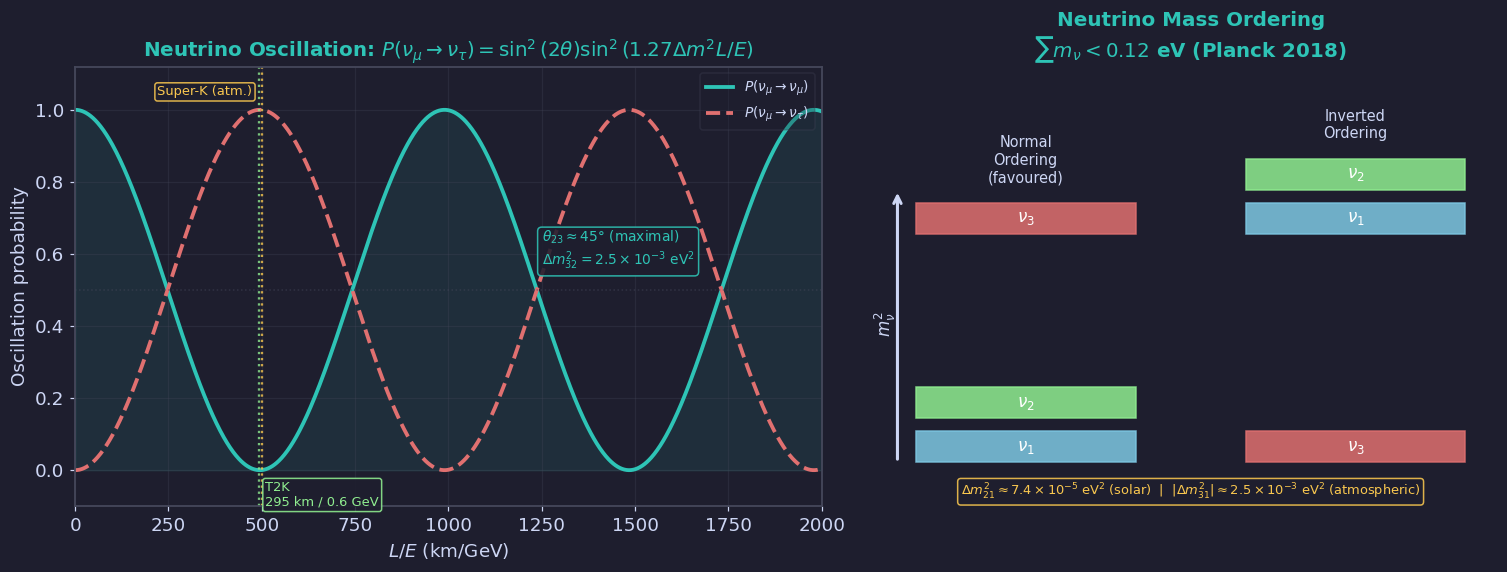

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5),
                         gridspec_kw={'width_ratios':[1.1, 0.9]})
fig.patch.set_facecolor(BG)

# ── Left: nu_mu survival probability ─────────────────────────────────────
ax = axes[0]; ax.set_facecolor(BG)
L_over_E = np.linspace(0, 2000, 1000)
theta23 = np.radians(45); Dm2_atm = 2.5e-3
P_mumu  = 1 - np.sin(2*theta23)**2 * np.sin(1.27*Dm2_atm*L_over_E)**2
P_mutau = 1 - P_mumu

ax.plot(L_over_E, P_mumu,  color=TEAL, lw=2.5, label=r'$P(\nu_\mu\to\nu_\mu)$')
ax.plot(L_over_E, P_mutau, color=RED,  lw=2.5, ls='--', label=r'$P(\nu_\mu\to\nu_\tau)$')
ax.fill_between(L_over_E, 0, P_mumu, color=TEAL, alpha=0.10)

# Super-K: label entirely above the curve peak (y=1.04), left of line
L_E_SK  = 500.0; L_E_T2K = 295/0.6
ax.axvline(L_E_SK,  color=YELL,  lw=1.5, ls=':', alpha=0.8)
ax.axvline(L_E_T2K, color=GREEN, lw=1.5, ls=':', alpha=0.8)
ax.text(L_E_SK - 25, 1.04, 'Super-K (atm.)',
        ha='right', fontsize=8.5, color=YELL,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=YELL, alpha=0.88))
# T2K: just below x-axis (negative y, inside ylim)
ax.text(L_E_T2K + 18, -0.03, 'T2K\n295 km / 0.6 GeV',
        ha='left', fontsize=8.5, color=GREEN, va='top',
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=GREEN, alpha=0.88))

# Parameter box: top-right empty region (between 1250–2000, y 0.55–0.90)
ax.text(1250, 0.57,
        r'$\theta_{23}\approx 45°$ (maximal)'+'\n'+
        r'$\Delta m^2_{32}=2.5\times10^{-3}$ eV$^2$',
        fontsize=9, color=TEAL,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=TEAL, alpha=0.88))

ax.axhline(0.5, color=EDGE, lw=1, ls=':', alpha=0.5)
ax.set_xlabel(r'$L/E$ (km/GeV)')
ax.set_ylabel('Oscillation probability')
# Single-line title to reduce top whitespace
ax.set_title(r'Neutrino Oscillation: $P(\nu_\mu\to\nu_\tau)'
             r'=\sin^2(2\theta)\sin^2(1.27\Delta m^2 L/E)$')
ax.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax.set_xlim(0, 2000); ax.set_ylim(-0.10, 1.12)
ax.grid(True, alpha=0.3)

# ── Right: Neutrino mass hierarchy ───────────────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)

# FIX: solar splitting too small to see (dm21_ratio~0.03).
# Use a MINIMUM visual gap of 0.10 for ν₁/ν₂ so they are distinguishable,
# while keeping ν₃ at the correct atmospheric-scale separation.
BAR = 0.07; GAP = 0.10; Y0 = 0.10

# Normal ordering
y1_N = Y0
y2_N = Y0 + GAP          # visually separated; label indicates actual Δm²₂₁
y3_N = Y0 + 0.52          # atmospheric scale above ν₁
for y, nu, col in [(y1_N, r'$\nu_1$', BLUE),
                   (y2_N, r'$\nu_2$', GREEN),
                   (y3_N, r'$\nu_3$', RED)]:
    ax2.add_patch(plt.Rectangle((0.05, y), 0.36, BAR, color=col, alpha=0.85))
    ax2.text(0.23, y + BAR/2, nu, ha='center', va='center',
             fontsize=11, color='white', fontweight='bold')

# Inverted ordering
y3_I = Y0
y1_I = Y0 + 0.52
y2_I = y1_I + GAP
for y, nu, col in [(y3_I, r'$\nu_3$', RED),
                   (y1_I, r'$\nu_1$', BLUE),
                   (y2_I, r'$\nu_2$', GREEN)]:
    ax2.add_patch(plt.Rectangle((0.59, y), 0.36, BAR, color=col, alpha=0.85))
    ax2.text(0.77, y + BAR/2, nu, ha='center', va='center',
             fontsize=11, color='white', fontweight='bold')

# Column headers — just above the top bar in each column
ax2.text(0.23, y3_N + BAR + 0.04, 'Normal\nOrdering\n(favoured)',
         ha='center', va='bottom', fontsize=9.5, color=FG)
ax2.text(0.77, y2_I + BAR + 0.04, 'Inverted\nOrdering',
         ha='center', va='bottom', fontsize=9.5, color=FG)

# y-axis arrow
ax2.annotate('', xy=(0.02, y3_N + BAR + 0.03),
             xytext=(0.02, Y0),
             arrowprops=dict(arrowstyle='->', color=FG, lw=2),
             xycoords='axes fraction', textcoords='axes fraction')
ax2.text(0.00, Y0 + 0.30, r'$m_\nu^2$',
         ha='center', fontsize=11, color=FG, rotation=90,
         transform=ax2.transAxes)

# Δm² values — centred at bottom
ax2.text(0.5, 0.01,
         r'$\Delta m^2_{21}\approx 7.4\times10^{-5}$ eV$^2$ (solar)  |  '
         r'$|\Delta m^2_{31}|\approx 2.5\times10^{-3}$ eV$^2$ (atmospheric)',
         ha='center', va='bottom', fontsize=8.5, color=YELL,
         bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=YELL, alpha=0.88))

ax2.set_title('Neutrino Mass Ordering\n'+r'$\sum m_\nu<0.12$ eV (Planck 2018)',
              color=TEAL)

plt.tight_layout(pad=1.5)
save('figures/ch04/fig03_neutrinos.png', fig)

---
## Ch05/fig02 · Dark Matter & Universe Budget (§5.2–5.3)

  saved -> figures/ch05/fig02_universe.png


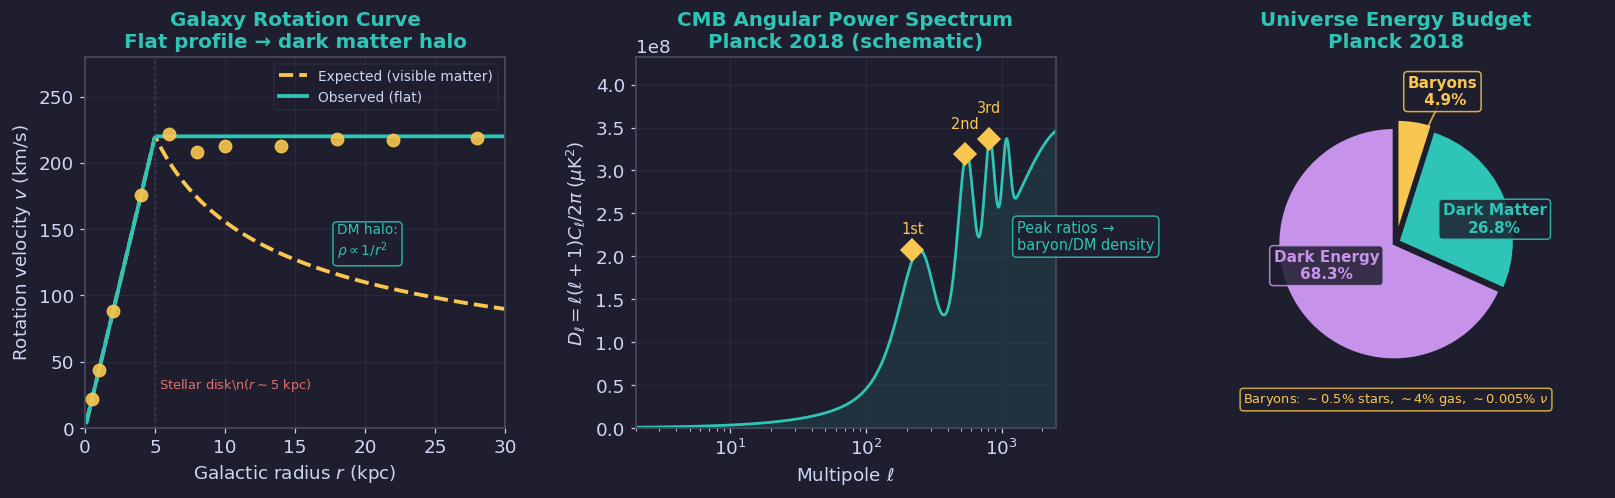

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Galaxy rotation curve ───────────────────────────────────────────
ax = axes[0]; ax.set_facecolor(BG)
r_gal = np.linspace(0.1, 30, 400); r_disk = 5.0
v_vis  = np.where(r_gal < r_disk, 220*(r_gal/r_disk), 220*np.sqrt(r_disk/r_gal))
v_flat = np.where(r_gal < r_disk, 220*(r_gal/r_disk), 220*np.ones_like(r_gal))
ax.plot(r_gal, v_vis,  color=YELL, lw=2.5, ls='--', label='Expected (visible matter)')
ax.plot(r_gal, v_flat, color=TEAL, lw=2.5, label='Observed (flat)')
np.random.seed(15)
r_data = np.array([0.5,1,2,4,6,8,10,14,18,22,28])
v_data = np.where(r_data < r_disk, 220*r_data/r_disk,
                  220*(1+0.03*np.random.randn(len(r_data))))
ax.scatter(r_data, v_data, color=YELL, s=65, zorder=5, alpha=0.9)
ax.axvline(r_disk, color=EDGE, lw=1.5, ls=':', alpha=0.6)
ax.text(r_disk+0.3, 30, r'Stellar disk\n($r\sim5$ kpc)', fontsize=8.5, color=RED)
ax.text(18, 130, 'DM halo:\n'+r'$\rho\propto 1/r^2$', fontsize=9, color=TEAL,
        bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=TEAL,alpha=0.85))
ax.set_xlabel('Galactic radius $r$ (kpc)')
ax.set_ylabel('Rotation velocity $v$ (km/s)')
ax.set_title('Galaxy Rotation Curve\nFlat profile → dark matter halo')
ax.legend(fontsize=9, labelcolor=FG)
ax.set_xlim(0,30); ax.set_ylim(0,280); ax.grid(True, alpha=0.3)

# ── Middle: CMB power spectrum ────────────────────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)
ell = np.arange(2, 2500)
C_ell = ((2000/ell)*np.exp(-ell/3000)
         *(1 + 2.0*np.exp(-0.5*((ell-220)/70)**2)
             + 1.2*np.exp(-0.5*((ell-540)/70)**2)
             + 0.7*np.exp(-0.5*((ell-810)/70)**2)
             + 0.4*np.exp(-0.5*((ell-1080)/70)**2)))
D_ell = ell*(ell+1)*C_ell/(2*np.pi)*1000; D_max = D_ell.max()

ax2.plot(ell, D_ell, color=TEAL, lw=1.8)
ax2.fill_between(ell, 0, D_ell, color=TEAL, alpha=0.12)
for ell_peak, lbl in [(220,'1st'),(540,'2nd'),(810,'3rd')]:
    D_pk = D_ell[np.abs(ell-ell_peak)<35].max()
    ax2.plot(ell_peak, D_pk, 'D', color=YELL, ms=10, zorder=5)
    ax2.text(ell_peak, D_pk*1.09, lbl, ha='center', fontsize=9.5, color=YELL)
ax2.text(1300, D_max*0.6, 'Peak ratios →\nbaryon/DM density',
         fontsize=9.5, color=TEAL,
         bbox=dict(boxstyle='round,pad=0.3',fc=BG,ec=TEAL,alpha=0.85))
ax2.set_xlabel(r'Multipole $\ell$')
ax2.set_ylabel(r'$D_\ell=\ell(\ell+1)C_\ell/2\pi\;(\mu{\rm K}^2)$')
ax2.set_title('CMB Angular Power Spectrum\nPlanck 2018 (schematic)')
ax2.set_xlim(2,2500); ax2.set_ylim(0, D_max*1.25)
ax2.set_xscale('log'); ax2.grid(True, alpha=0.3)

# ── Right: Universe budget pie (labels with leader lines, no overlap) ─────
ax3 = axes[2]; ax3.set_facecolor(BG)
sizes = [68.3, 26.8, 4.9]
cols  = [PURP, TEAL, YELL]
wedges, _ = ax3.pie(sizes, colors=cols, startangle=90,
                    wedgeprops={'linewidth':1.8,'edgecolor':BG}, labels=None,
                    explode=[0.02, 0.02, 0.06])

label_data = [
    (0, 'Dark Energy',   '68.3%', -0.60,-0.20, PURP),
    (1, 'Dark Matter',   '26.8%',  0.85, 0.20, TEAL),
    (2, 'Baryons',       ' 4.9%',  0.40, 1.30, YELL),
]
for idx,name,pct,lx,ly,col in label_data:
    theta = (sum(sizes[:idx])+sizes[idx]/2)/100*360+90
    wx,wy = 0.65*np.cos(np.radians(theta)), 0.65*np.sin(np.radians(theta))
    ax3.annotate('',xy=(wx,wy),xytext=(lx*0.98,ly*0.95),
                 arrowprops=dict(arrowstyle='-',color=col,lw=1.2,alpha=0.8))
    ax3.text(lx, ly, name+'\n'+pct, ha='center', va='center',
             fontsize=10, color=col, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.25',fc=BG,ec=col,alpha=0.85))
ax3.text(0, -1.38, r'Baryons: $\sim$0.5% stars, $\sim$4% gas, $\sim$0.005% $\nu$',
         ha='center', fontsize=8.5, color=YELL,
         bbox=dict(boxstyle='round,pad=0.25',fc=BG,ec=YELL,alpha=0.80))
ax3.set_title('Universe Energy Budget\nPlanck 2018', color=TEAL)
ax3.set_xlim(-1.8,1.8); ax3.set_ylim(-1.6,1.6)

plt.tight_layout(pad=1.5)
save('figures/ch05/fig02_universe.png', fig)


In [7]:
import shutil
from google.colab import files

for ch in ['ch03','ch04','ch05']:
    shutil.make_archive(f'particle_{ch}_figures', 'zip', '.', f'figures/{ch}')
    files.download(f'particle_{ch}_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>